# TSM-CAM: Open Route Test (No Return)
Start in Phnom Penh, visit all three destinations once, and stop at the last city. Keep 16 qubits, p = 1, 1,024 shots and COBYLA maxiter = 30 for comparison. No return edge is optimized or displayed.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# When saved in tsm-cam, the current directory or its parent is detected.
# Change PROJECT_ROOT manually if your project is somewhere else.
search_roots = [Path.cwd(), *Path.cwd().parents,
                Path('/Users/nak/CADT/projects/tsm-cam')]
PROJECT_ROOT = next((p for p in search_roots
                     if (p / 'app/quantum/qaoa.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Set PROJECT_ROOT to your tsm-cam directory.')
sys.path.insert(0, str(PROJECT_ROOT))

from app.classical.locations import build_straight_distance_matrix
from app.quantum.qaoa import create_graph, create_hamiltonian

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})
NAVY, TEAL, PURPLE = '#08134d', '#008c95', '#8046e8'
print('Project:', PROJECT_ROOT)


Project: /Users/nak/CADT/projects/tsm-cam


## 1. Read locations and resolve coordinates

Load the departure and destinations with their coordinates. Nodes represent cities; connections are straight lines.

0: Phnom Penh: lat=11.57, lon=104.92
1: Takeo: lat=10.99, lon=104.78
2: Kampong Cham: lat=11.99, lon=105.46
3: Siem Reap: lat=13.36, lon=103.86


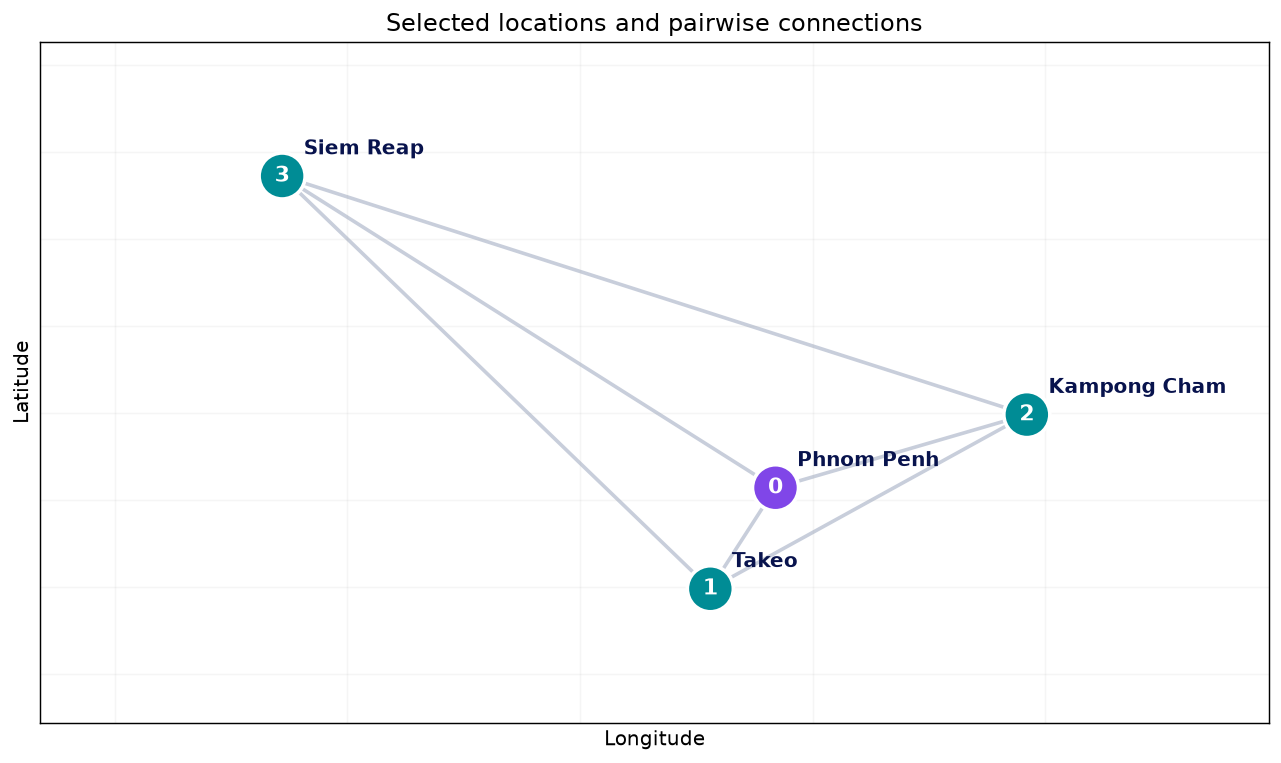

In [2]:
CITY_NAMES = ['Phnom Penh', 'Takeo', 'Kampong Cham', 'Siem Reap']
province_pins = json.loads((PROJECT_ROOT / 'static/data/provinces.json').read_text())
by_name = {p['name'].casefold(): p for p in province_pins}
assert 2 <= len(CITY_NAMES) <= 4, 'Select departure plus 1–3 destinations.'
assert len(set(n.casefold() for n in CITY_NAMES)) == len(CITY_NAMES)
locations = [dict(by_name[name.casefold()]) for name in CITY_NAMES]
n = len(locations)
for i, location in enumerate(locations):
    print(f"{i}: {location['name']}: lat={location['latitude']}, lon={location['longitude']}")

positions = {i: (p['longitude'], p['latitude']) for i, p in enumerate(locations)}
node_colors = [PURPLE if i == 0 else TEAL for i in range(n)]
fig, ax = plt.subplots(figsize=(10, 6))
graph = nx.complete_graph(n)
nx.draw_networkx_edges(graph, positions, ax=ax, edge_color='#c8cedb', width=2)
nx.draw_networkx_nodes(graph, positions, ax=ax, node_color=node_colors,
                       node_size=650, edgecolors='white', linewidths=2)
nx.draw_networkx_labels(graph, positions, labels={i: str(i) for i in range(n)},
                        ax=ax, font_color='white', font_weight='bold')
for i, (lon, lat) in positions.items():
    ax.annotate(locations[i]['name'], (lon, lat), xytext=(12, 12),
                textcoords='offset points', color=NAVY, fontweight='bold')
ax.set(xlabel='Longitude', ylabel='Latitude',
       title='Selected locations and pairwise connections')
ax.margins(0.25)
ax.grid(alpha=0.12)
plt.tight_layout()
plt.show()


## 2. Calculate distances and build the matrix

Calculate pairwise Haversine distances. Each matrix entry is a distance in kilometers.

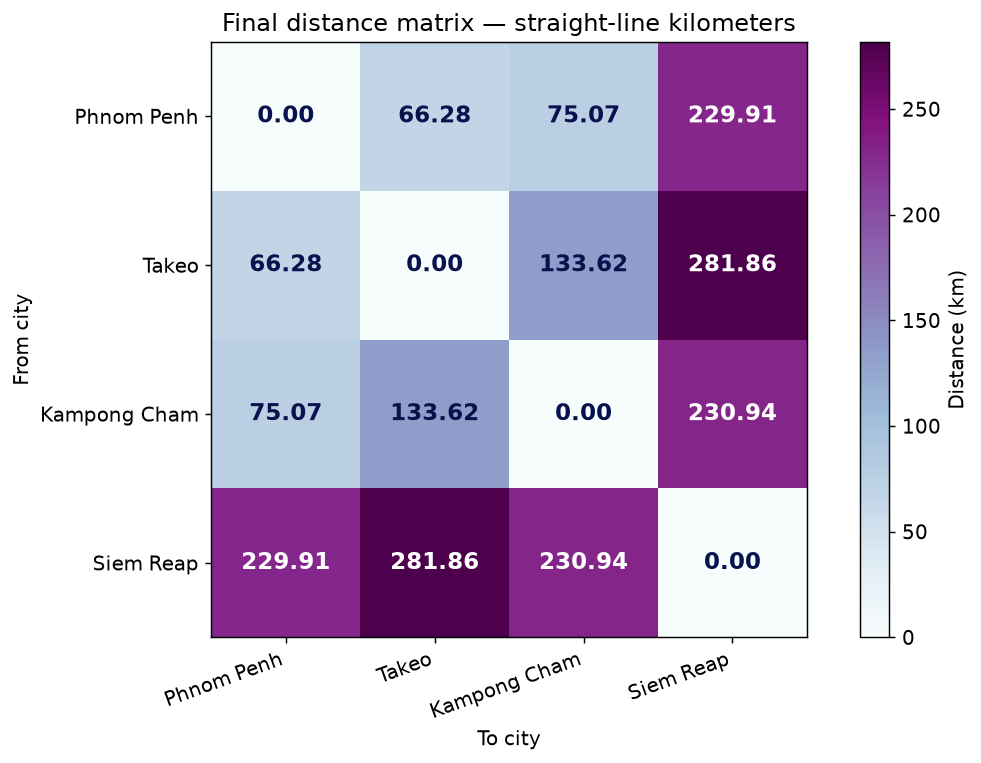

Numeric matrix passed to the TSP model:
[[  0.    66.28  75.07 229.91]
 [ 66.28   0.   133.62 281.86]
 [ 75.07 133.62   0.   230.94]
 [229.91 281.86 230.94   0.  ]]


In [3]:
matrix_data = build_straight_distance_matrix(locations)
distance_matrix = np.asarray(matrix_data['distances'], dtype=float)
assert distance_matrix.shape == (n, n)
assert np.allclose(distance_matrix, distance_matrix.T)
assert np.allclose(np.diag(distance_matrix), 0)

fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(distance_matrix, cmap='BuPu', vmin=0)
ax.set_xticks(range(n), CITY_NAMES, rotation=20, ha='right')
ax.set_yticks(range(n), CITY_NAMES)
ax.set(xlabel='To city', ylabel='From city',
       title='Final distance matrix — straight-line kilometers')
for i in range(n):
    for j in range(n):
        color = 'white' if distance_matrix[i, j] > distance_matrix.max() * 0.6 else NAVY
        ax.text(j, i, f'{distance_matrix[i, j]:.2f}', ha='center', va='center',
                color=color, fontsize=13, fontweight='bold')
fig.colorbar(heatmap, ax=ax, label='Distance (km)')
plt.tight_layout()
plt.show()
print('Numeric matrix passed to the TSP model:')
print(np.array2string(distance_matrix, precision=2, suppress_small=True))


In [4]:
def route_names(tour):
    return ' → '.join(CITY_NAMES[i] for i in tour)

def tour_distance(tour):
    return float(sum(distance_matrix[a, b] for a, b in zip(tour, tour[1:])))



## 3. Encode an open route
Minimize only the three consecutive legs. Require each city once, one city per position, and Phnom Penh at position 1. Build the Hamiltonian from this changed objective.

In [5]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.translators import to_ising

weighted_graph = create_graph(distance_matrix)
problem = QuadraticProgram('Open route from Phnom Penh')
for city in range(n):
    for position in range(n):
        problem.binary_var(name=f'x_{city}_{position}')

# No last-position → first-position term.
quadratic = {}
for position in range(n-1):
    for a in range(n):
        for b in range(n):
            if a != b:
                quadratic[(f'x_{a}_{position}', f'x_{b}_{position+1}')] = float(distance_matrix[a,b])
problem.minimize(quadratic=quadratic)
for city in range(n):
    problem.linear_constraint({f'x_{city}_{position}': 1 for position in range(n)}, '==', 1, f'visit_city_{city}')
for position in range(n):
    problem.linear_constraint({f'x_{city}_{position}': 1 for city in range(n)}, '==', 1, f'fill_position_{position}')
problem.linear_constraint({'x_0_0': 1}, '==', 1, 'start_at_phnom_penh')
converter = QuadraticProgramToQubo()
qubo = converter.convert(problem)
hamiltonian, offset = to_ising(qubo)
print('Cities:', n, '| Qubits:', hamiltonian.num_qubits)
print('Route legs:', n-1, '| Return edge: excluded | Start: Phnom Penh')
print('Pauli terms:', len(hamiltonian.paulis))
print('Penalty:', converter.penalty)
# Check all six valid open-route assignments against the actual objective.
from itertools import permutations
for order in permutations(range(1,n)):
    route = [0, *order]
    bits = np.zeros((n,n), dtype=int)
    for position, city in enumerate(route):
        bits[city,position] = 1
    assert np.isclose(problem.objective.evaluate(bits.reshape(-1)), tour_distance(route))
    assert problem.is_feasible(bits.reshape(-1))
    assert np.isclose(qubo.objective.evaluate(bits.reshape(-1)), tour_distance(route))
print('Verified open-route objective and constraints for all six valid orders.')

Cities: 4 | Qubits: 16
Route legs: 3 | Return edge: excluded | Start: Phnom Penh
Pauli terms: 100
Penalty: 6107.145075387225
Verified open-route objective and constraints for all six valid orders.


## 4. Quantum processing: QAOA and measurement

Reuse the Step 3 Hamiltonian in QAOA, simulated by Aer with classical COBYLA optimization.

### 4.1 Configure QAOA

Fix shots at 1,024. Set initial angles, one QAOA layer and COBYLA.

In [6]:
from qiskit import transpile
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.minimum_eigensolvers import QAOA

INITIAL_GAMMA = 0.2
INITIAL_BETA = 0.2
SHOTS = 1024
backend = AerSimulator(max_parallel_threads=4)
pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
sampler = SamplerV2(default_shots=SHOTS, seed=42,
    options={'backend_options': {'max_parallel_threads': 4}})
print('Shots per evaluation and final sampling:', SHOTS)
print('QAOA layers: 1 | COBYLA maxiter: 30')

Shots per evaluation and final sampling: 1024
QAOA layers: 1 | COBYLA maxiter: 30


### 4.2 Optimize beta and gamma

COBYLA adjusts the angles, not the shot count. The graph shows sampled energy.

Optimized [beta, gamma]: [0.20245247 0.19951481]


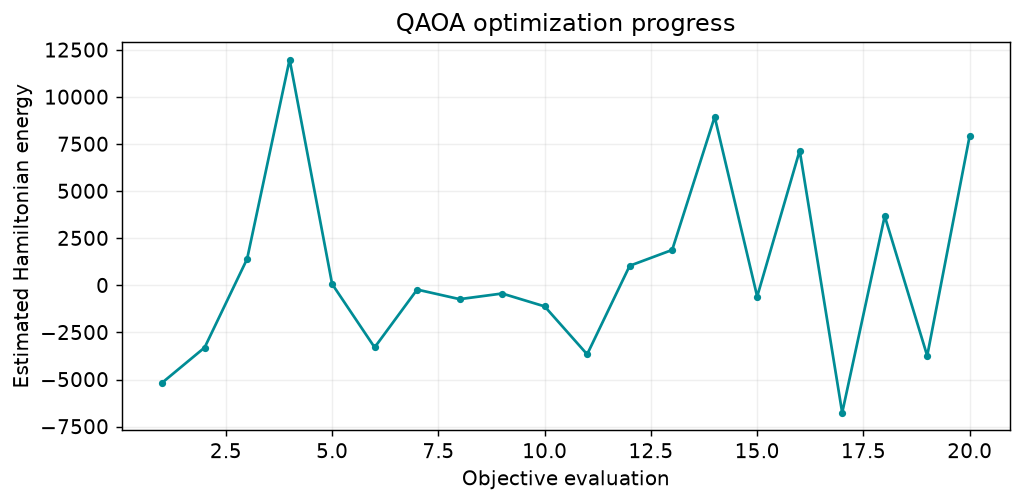

In [7]:
optimization_log = []
def record_evaluation(evaluation, parameters, mean, metadata):
    energy = float(np.real(mean))
    optimization_log.append((int(evaluation), energy))

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=30, tol=1e-3),
    reps=1,
    pass_manager=pass_manager,
    initial_point=np.array([INITIAL_BETA, INITIAL_GAMMA]),
    callback=record_evaluation,
)
qaoa_result = qaoa.compute_minimum_eigenvalue(hamiltonian)
print('Optimized [beta, gamma]:', qaoa_result.optimal_point)

evaluations, energies = zip(*optimization_log)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(evaluations, energies, 'o-', color=TEAL, markersize=3)
ax.set(xlabel='Objective evaluation', ylabel='Estimated Hamiltonian energy',
       title='QAOA optimization progress')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 4.3 Measure the optimized result

Sample 1,024 bitstrings. The chart shows actual counts; some assignments may be invalid.

Final sampling shots: 1024
Unique measured bitstrings: 1008


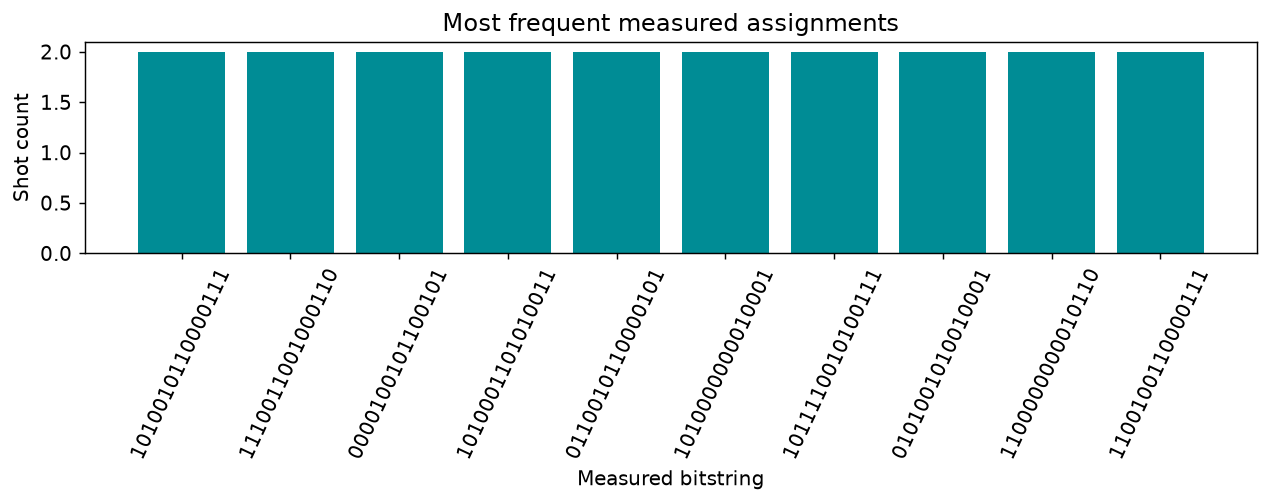

In [8]:
circuit = qaoa.ansatz.remove_final_measurements(inplace=False)
circuit = circuit.assign_parameters(qaoa_result.optimal_point)
circuit.measure_all()
compiled = transpile(circuit, backend, seed_transpiler=42)
counts = backend.run(compiled, shots=SHOTS, seed_simulator=42).result().get_counts()
assert sum(counts.values()) == SHOTS
print('Final sampling shots:', sum(counts.values()))
print('Unique measured bitstrings:', len(counts))

top_counts = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:10]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([bits for bits, count in top_counts], [count for bits, count in top_counts], color=TEAL)
ax.set(xlabel='Measured bitstring', ylabel='Shot count', title='Most frequent measured assignments')
ax.tick_params(axis='x', rotation=65)
plt.tight_layout()
plt.show()

### 4.4 Decode and validate candidates (classical)

Keep valid tours and remove duplicates. Check the optimizer’s best measurement separately without changing final counts.

In [9]:
def decode_tour(bitstring):
    assignment = np.array([int(bit) for bit in bitstring[::-1]]).reshape(n, n)
    if not (np.all(assignment.sum(axis=0) == 1) and np.all(assignment.sum(axis=1) == 1)):
        return None
    cycle = [int(np.argmax(assignment[:, p])) for p in range(n)]
    if cycle[0] != 0:
        return None
    return cycle

candidates = []
seen = set()
valid_shots = 0
for bitstring, count in counts.items():
    tour = decode_tour(bitstring)
    if tour is None:
        continue
    valid_shots += count
    if tuple(tour) not in seen:
        seen.add(tuple(tour))
        candidates.append({'tour': tour, 'bitstring': bitstring, 'source': 'Final sampling'})

best_measurement = getattr(qaoa_result, 'best_measurement', None) or {}
best_bitstring = best_measurement.get('bitstring')
best_tour = decode_tour(best_bitstring) if best_bitstring else None
if best_tour is not None and tuple(best_tour) not in seen:
    candidates.append({'tour': best_tour, 'bitstring': best_bitstring, 'source': 'Optimizer measurement'})

print(f'Valid final shots: {valid_shots}/{SHOTS} ({100*valid_shots/SHOTS:.2f}%)')
print('Valid unique route candidates:', len(candidates))
for candidate in sorted(candidates, key=lambda item: tour_distance(item['tour'])):
    print(f"{tour_distance(candidate['tour']):.2f} km | {route_names(candidate['tour'])} | {candidate['source']}")
if not candidates:
    print('No valid open route measured in this run; no route will be substituted.')

Valid final shots: 0/1024 (0.00%)
Valid unique route candidates: 1
587.88 km | Phnom Penh → Kampong Cham → Siem Reap → Takeo | Optimizer measurement


## 5. Select and visualize the open route
Select the shortest valid measured candidate. Do not append Phnom Penh or rotate positions. If no valid candidate was measured, report that outcome.

SELECTED QAOA ROUTE
Candidate source: Optimizer measurement
Phnom Penh → Kampong Cham → Siem Reap → Takeo
Total straight-line distance: 587.88 km
Selected measured bitstring: 0100001010000001


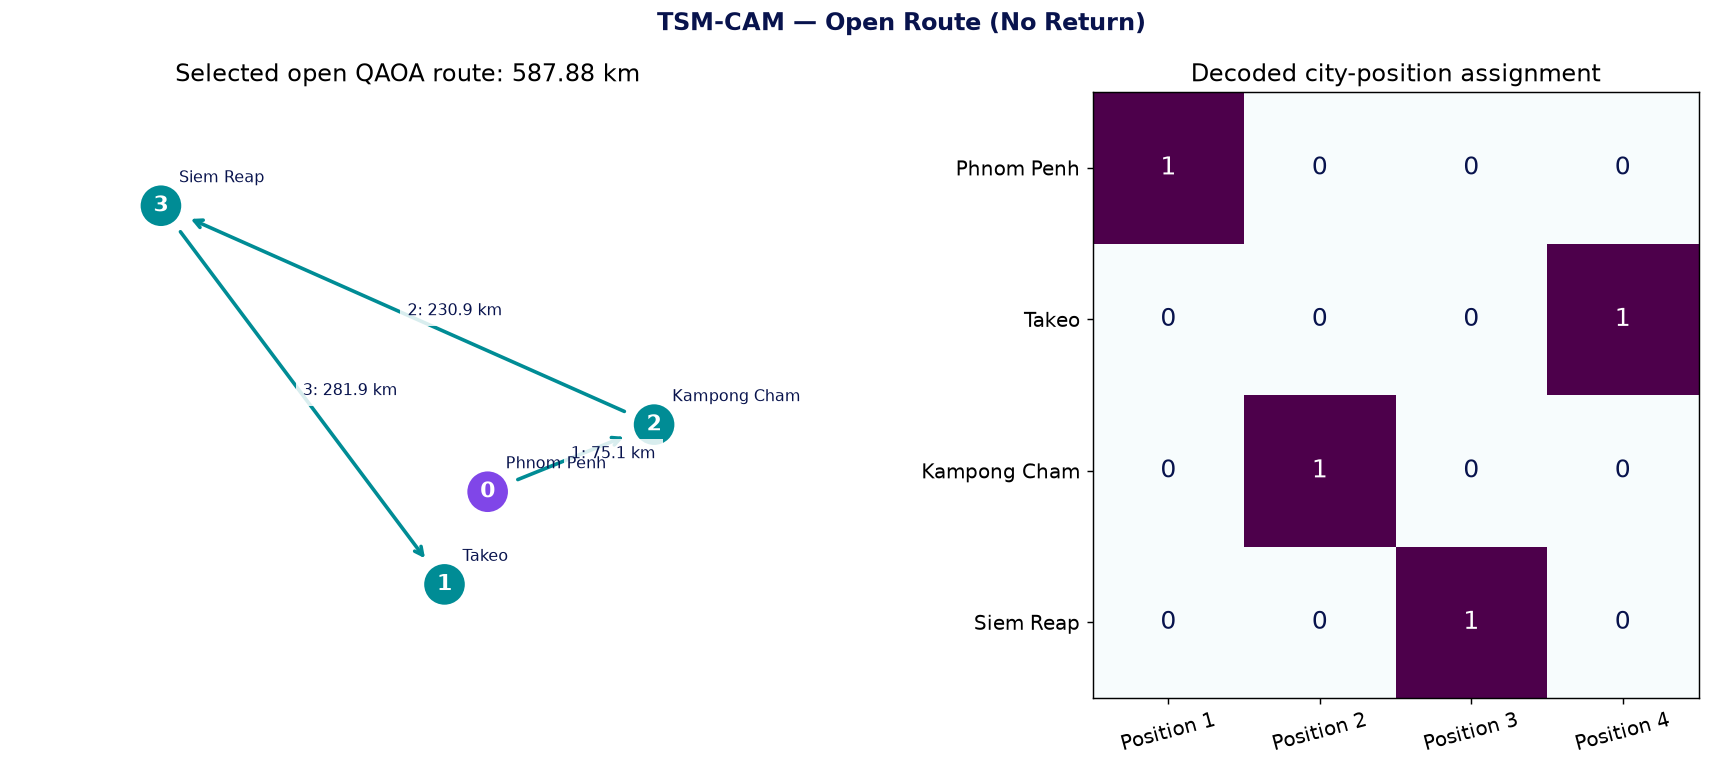

In [10]:
selected = None
if candidates:
    selected = min(candidates, key=lambda candidate: tour_distance(candidate['tour']))
    selected_tour = selected['tour']
    selected_distance = tour_distance(selected_tour)
    print('SELECTED QAOA ROUTE')
    print('Candidate source:', selected['source'])
    print(route_names(selected_tour))
    print(f'Total straight-line distance: {selected_distance:.2f} km')
    print('Selected measured bitstring:', selected['bitstring'])

    assignment = np.array([int(bit) for bit in reversed(selected['bitstring'])]).reshape(n, n)
    assert [int(np.flatnonzero(assignment[:, p])[0]) for p in range(n)] == selected_tour
    assert np.all(assignment.sum(axis=0) == 1)
    assert np.all(assignment.sum(axis=1) == 1)

    fig, (ax_route, ax_assignment) = plt.subplots(1, 2, figsize=(14, 6))
    nx.draw_networkx_nodes(weighted_graph, positions, ax=ax_route, node_color=node_colors,
                           node_size=600, edgecolors='white', linewidths=2)
    nx.draw_networkx_labels(weighted_graph, positions, labels={i: str(i) for i in range(n)},
                            ax=ax_route, font_color='white', font_weight='bold')
    for step, (a, b) in enumerate(zip(selected_tour, selected_tour[1:]), 1):
        ax_route.annotate('', xy=positions[b], xytext=positions[a],
                          arrowprops=dict(arrowstyle='->', color=TEAL, lw=2,
                                          shrinkA=18, shrinkB=18))
        x = (positions[a][0] + positions[b][0]) / 2
        y = (positions[a][1] + positions[b][1]) / 2
        ax_route.text(x, y, f'{step}: {distance_matrix[a,b]:.1f} km', fontsize=9,
                      color=NAVY, bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
    for i, (lon, lat) in positions.items():
        ax_route.annotate(CITY_NAMES[i], (lon, lat), xytext=(10, 13),
                          textcoords='offset points', fontsize=9, color=NAVY)
    ax_route.margins(0.3)
    ax_route.set_title(f'Selected open QAOA route: {selected_distance:.2f} km')
    ax_route.set_axis_off()
    ax_assignment.imshow(assignment, cmap='BuPu', vmin=0, vmax=1)
    ax_assignment.set_xticks(range(n), [f'Position {p+1}' for p in range(n)], rotation=15)
    ax_assignment.set_yticks(range(n), CITY_NAMES)
    ax_assignment.set_title('Decoded city-position assignment')
    for i in range(n):
        for j in range(n):
            ax_assignment.text(j, i, str(assignment[i,j]), ha='center', va='center',
                               color='white' if assignment[i,j] else NAVY, fontsize=14)
    fig.suptitle('TSM-CAM — Open Route (No Return)', color=NAVY, fontweight='bold')
    plt.tight_layout()
    plt.show()

else:
    print('No QAOA open route to display.')

## Separate classical benchmark
Enumerate open routes only after QAOA. Compare distances when a valid measured candidate exists; never use the benchmark as a replacement.

In [11]:
from itertools import permutations
benchmark_tours = [[0, *order] for order in permutations(range(1,n))]
classical_best = min(benchmark_tours, key=tour_distance)
classical_distance = tour_distance(classical_best)
print('Exact open route:', route_names(classical_best))
print(f'Exact open distance: {classical_distance:.2f} km')
print(f'Valid final shots: {valid_shots}/{SHOTS}')
if selected is not None:
    gap = 100*(selected_distance-classical_distance)/classical_distance
    print(f'QAOA candidate distance: {selected_distance:.2f} km')
    print(f'Gap: {gap:.2f}%')
    print('Candidate source:', selected['source'])
    assert selected_tour[0] == 0 and len(selected_tour) == n and len(set(selected_tour)) == n
    assert selected_distance >= classical_distance - 1e-7
else:
    print('No valid measured QAOA candidate for comparison.')

Exact open route: Phnom Penh → Takeo → Kampong Cham → Siem Reap
Exact open distance: 430.84 km
Valid final shots: 0/1024
QAOA candidate distance: 587.88 km
Gap: 36.45%
Candidate source: Optimizer measurement
